In [48]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [49]:
shots = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/shots.csv")
teams = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/teams.csv")

In [111]:
#"26-27-prem-brighton-hove-albion-vs-aston-villa".split("vs")[0].split("prem")[1].split("-")
def home_away(match_id):
    home, away = match_id.split("vs")
    home = home.split("prem")[1].split("-")
    home = ' '.join(home).strip()
    away = away.split("-")
    away = ' '.join(away).strip()

    return home, away

In [126]:
def shot_map(match):
    POST_LEFT = 54.8
    POST_RIGHT = 45.2

    match["goal_y_relative"] = (
        (POST_LEFT - match["goal_mouth_y"]) / (POST_LEFT - POST_RIGHT)
    ) * 100

    CROSSBAR_HEIGHT = 100.0 / 3.0
    match["goal_z_relative"] = (match["goal_mouth_z"] / 100.0) * CROSSBAR_HEIGHT

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot([0, 0, 100, 100], [0, CROSSBAR_HEIGHT, CROSSBAR_HEIGHT, 0], color="white", lw=3)

    ax.scatter(
        match["goal_y_relative"],
        match["goal_z_relative"],
        edgecolors="black",
        s=120,
        zorder=3,
    )

    x_min = min(-20, match["goal_y_relative"].min() - 30)
    x_max = max(120, match["goal_y_relative"].max() + 30)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-5, CROSSBAR_HEIGHT + 10)

    ax.set_aspect("equal", adjustable="box")

    # Dark Mode Styling
    fig.patch.set_facecolor("#121212")
    ax.set_facecolor("#121212")
    ax.axis("off")

    plt.show()

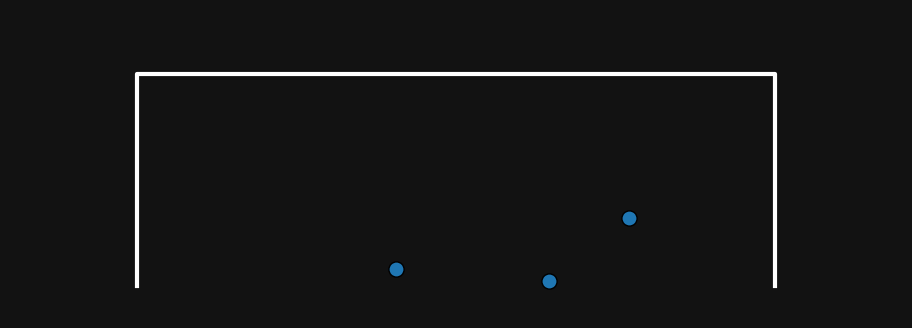

In [127]:
def shot_map_data(match_id, outcome):
    match = shots[shots["match_id"] == match_id]
    str = match_id.split("-")
    home, away = home_away(match_id)
    match["team_name"] = np.where (
        match['is_home'], home, away
    )
    match = match[match["outcome"] == outcome]
    shot_map(match)

shot_map_data("26-27-prem-brentford-vs-tottenham-hotspur", 'goal')